## Notebook 02: Exploratory Data Analysis & Feature Interdependencies

---

### 1. Architectural Role & Project Context
Before engineering features or training machine learning models, exploratory data analysis (EDA) is essential to uncover:
- Non-linear relationships between upstream hazard signals and final emergency priority levels.
- Interaction effects between environmental conditions (e.g. rainfall runoff) and population exposure.
- How telemetry health (LoRa latency and stale sensor data) impacts decision confidence.
- Feature distributions and potential collinearities across the Kelani River catchment zones.

---

### 2. Linked Source Scripts & Data
- **`src/component04_ml/__init__.py`**: Provides `get_project_root()` for robust directory resolution.
- **`data/raw/synthetic_disaster_scenarios.csv`**: The primary dataset generated by `src/component04_ml/data_generation.py`.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

train_path = root_dir / "data" / "processed" / "train_scenarios.csv"
df = pd.read_csv(train_path)
print(f"Loaded training data: {df.shape[0]} scenarios, {df.shape[1]} columns")


Loaded training data: 3000 scenarios, 18 columns


### Section 1: Key Numerical Features Summary Statistics
Here we examine the central tendencies, dispersion, and extreme ranges across key physical, operational, and network telemetry variables:
- `contamination_probability`: Upstream ML prediction of toxic effluent / pollutant risk.
- `estimated_exposed_population`: Inhabitants dependent on water source in the affected reach.
- `communication_delay_seconds`: Latency across the riverboat LoRa mesh telemetry network.
- `sensor_data_freshness_seconds`: Elapsed time since the last valid physical sensor packet.
- `rainfall_mm`: Recent precipitation intensity driving surface runoff and drainage washouts.


In [2]:
key_num = [
    "contamination_probability",
    "prediction_confidence",
    "estimated_exposed_population",
    "communication_delay_seconds",
    "rainfall_mm",
    "sensor_data_freshness_seconds"
]
df[key_num].describe().round(2)


,contamination_probability,prediction_confidence,estimated_exposed_population,communication_delay_seconds,rainfall_mm,sensor_data_freshness_seconds
count,3000.00,2614.00,3000.00,3000.00,3000.00,3000.00
mean,0.42,0.88,9042.61,528.87,11.04,833.18
std,0.28,0.07,17803.58,1350.06,19.60,1387.68
min,0.01,0.60,50.00,2.00,0.00,10.00
25%,0.15,0.83,1562.00,22.20,0.00,157.95
50%,0.41,0.88,3825.00,42.60,0.00,355.20
75%,0.64,0.94,9157.25,195.18,15.22,791.72
max,0.99,0.99,282994.00,7188.70,134.70,8636.10


### Section 2: Contamination Probability vs Disaster Response Priority
#### Operational Analysis:
In standard water monitoring, priority is often tied solely to chemical thresholds. In a multi-dimensional DRR framework:
- **P1 (Critical)** and **P2 (High)** show higher median contamination probabilities, but overlapping distributions exist.
- Notice that even moderate contamination ($P \approx 0.5-0.6$) can trigger **P1** if exposed population is extremely dense or if critical municipal intakes are threatened.
- Conversely, high contamination ($P > 0.8$) in an uninhabited, non-critical agricultural buffer with low exposure may result in **P2** or **P3** rather than an all-out municipal shutdown.


C:\Users\User\AppData\Local\Temp\ipykernel_9496\755731.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="priority_level", y="contamination_probability", order=["P1", "P2", "P3", "P4"], palette=palette, ax=ax)


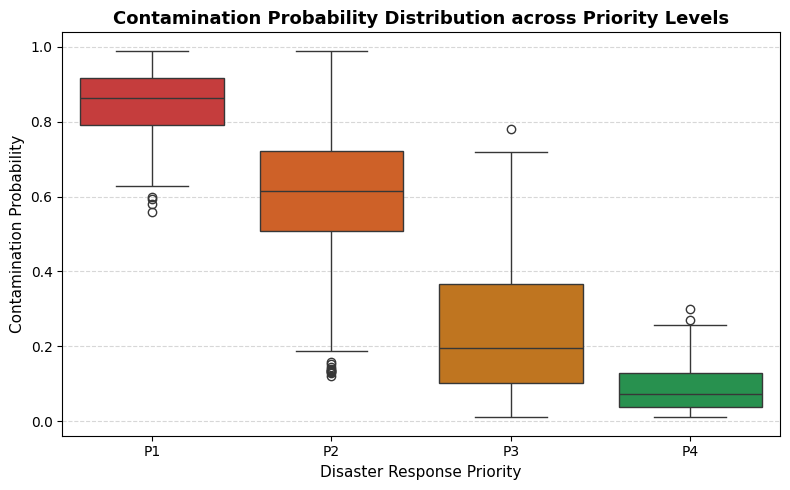

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
palette = {"P1": "#dc2626", "P2": "#ea580c", "P3": "#d97706", "P4": "#16a34a"}
sns.boxplot(data=df, x="priority_level", y="contamination_probability", order=["P1", "P2", "P3", "P4"], palette=palette, ax=ax)
ax.set_title("Contamination Probability Distribution across Priority Levels", fontsize=13, fontweight="bold")
ax.set_xlabel("Disaster Response Priority", fontsize=11)
ax.set_ylabel("Contamination Probability", fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### Section 3: Population Exposure vs Contamination Hazard
#### Socio-Hydrological Risk Surface:
Disaster risk is formalized as:
$$\text{Risk} = \text{Hazard} \times \text{Exposure} \times \text{Vulnerability}$$
- The scatter and density plot below visualizes the two-dimensional risk space ($\{P(\text{contam}), \log_{10}(\text{population})\}$).
- High hazard coupled with populations exceeding $10^4-10^5$ citizens clusters exclusively into the P1 Critical zone.


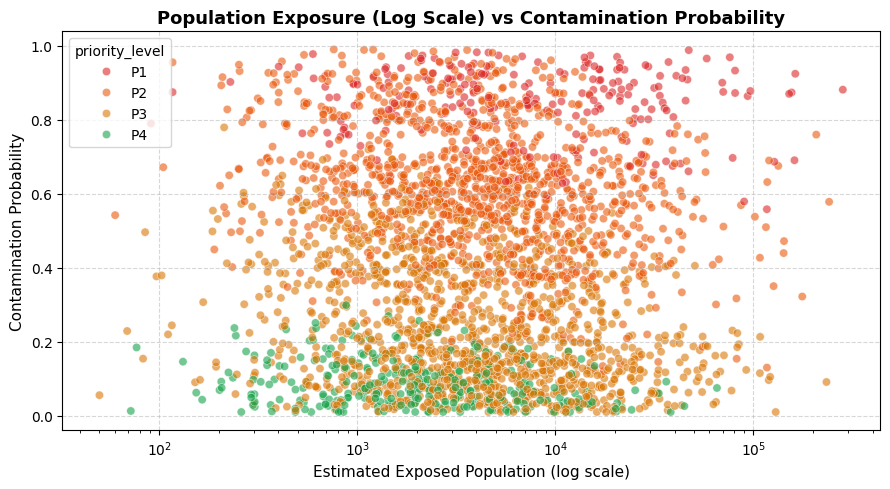

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="estimated_exposed_population",
    y="contamination_probability",
    hue="priority_level",
    hue_order=["P1", "P2", "P3", "P4"],
    palette=palette,
    alpha=0.6,
    ax=ax
)
ax.set_xscale("log")
ax.set_title("Population Exposure (Log Scale) vs Contamination Probability", fontsize=13, fontweight="bold")
ax.set_xlabel("Estimated Exposed Population (log scale)", fontsize=11)
ax.set_ylabel("Contamination Probability", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### Section 4: Correlation Matrix of Numerical Features
#### Collinearity & Orthogonality Check:
- Evaluates Pearson correlation coefficients across numerical inputs.
- Verifies that telemetry delay, sensor freshness, and rainfall provide distinct, non-redundant operational information to downstream tree-based classifiers.


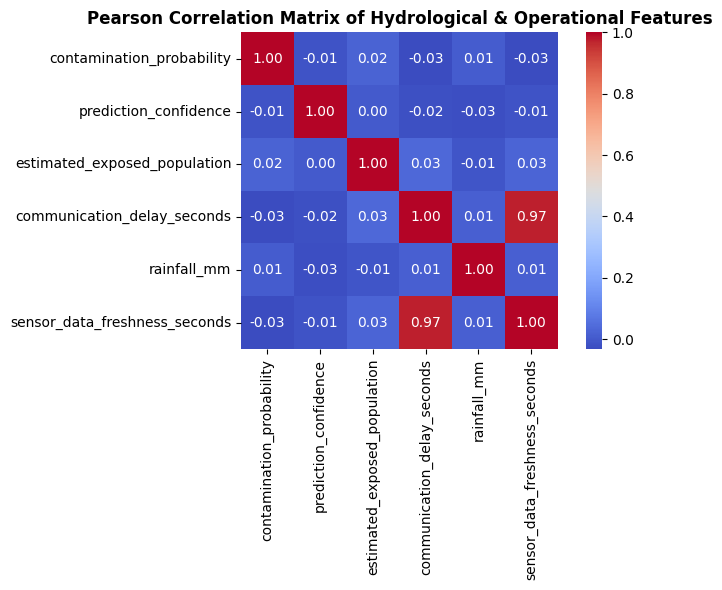

In [5]:
corr = df[key_num].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, ax=ax, square=True)
ax.set_title("Pearson Correlation Matrix of Hydrological & Operational Features", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Section 5: Critical Infrastructure & Catchment Vulnerability
#### Cross-Tabulation Analysis:
- Explores how facility importance (`CRITICAL`, `MAJOR`, `STANDARD`, `MINOR`) shapes response priority.
- Scenarios involving `CRITICAL` infrastructure (e.g. Ambathale/Kelani municipal water intakes) disproportionately command P1 and P2 actions, ensuring public health safeguards even under partial data uncertainty.


Percentage Priority Distribution by Infrastructure Importance:
priority_level               P1    P2    P3    P4
infrastructure_importance                        
CRITICAL                   20.2  45.7  34.1   0.0
MAJOR                       8.1  46.0  45.0   0.9
MINOR                       1.9  26.9  40.7  30.4
STANDARD                    3.0  36.6  45.1  15.4


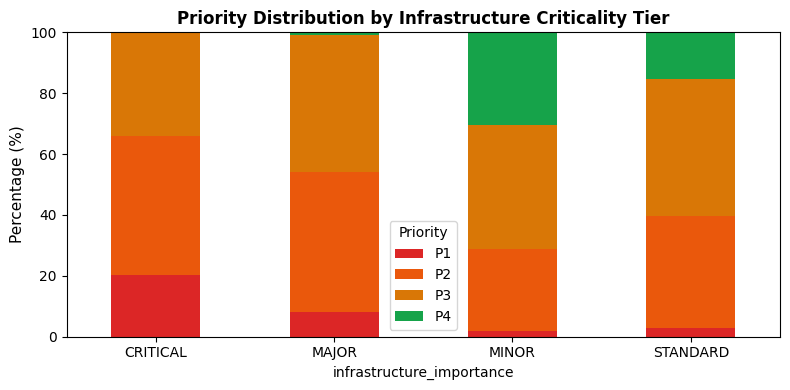

In [6]:
ct = pd.crosstab(df["infrastructure_importance"], df["priority_level"], normalize="index") * 100
print("Percentage Priority Distribution by Infrastructure Importance:")
print(ct.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ct[["P1", "P2", "P3", "P4"]].plot(kind="bar", stacked=True, color=["#dc2626", "#ea580c", "#d97706", "#16a34a"], ax=ax)
ax.set_title("Priority Distribution by Infrastructure Criticality Tier", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage (%)", fontsize=11)
ax.legend(title="Priority")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
